# Exemple 11 : runs using corrected projections - multimodel

The aim of this notebook is to provide, in response to a user issue (https://github.com/SARRA-cropmodels/SARRA-Py/issues/8), a full working example of simulation performed using data provided in NetCDF format ; also as this example covers Brazil, it cannot use the initially implemented helper functions for the preparation of soil properties data (as they were based on iSDA Africa datasets). Hence, this notebook will prepare a simulation using dummy soil properties values.

## Imports

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
from contextlib import ExitStack
import datetime
from matplotlib import pyplot as plt
from tqdm import tqdm as tqdm
import xarray as xr
from sarra_py import *
from sarra_py import ModelParameters, SimulationConfig, load_model_parameters, run_simulation as run_sarra_simulation, select_daily_window, validate_input_dataset
import geopandas as gpd
from joblib import Parallel, delayed
import xarray as xr
import numpy as np
import datetime
from tqdm import tqdm
import os

The example discovers model triplets in the configured climate directory. The repository includes one compatible triplet; add more NetCDF files there to compare more models.


In [ ]:
# Set this directory to a larger climate collection to run more models.
# The included example 10 collection provides one complete model triplet.
CLIMATE_DIR = Path("../data/exemple_data/exemple_10")
records = []
for path in sorted(CLIMATE_DIR.glob("*.nc")):
    parts = path.name.split("_")
    if len(parts) < 10 or parts[1] not in {"pr", "tasmax", "tasmin"}:
        continue
    records.append({
        "filename": path.name,
        "correction": parts[0],
        "variable": parts[1],
        "full_model": f"{parts[3]} / {parts[-4]}",
    })
files = pd.DataFrame(records)
if files.empty:
    raise FileNotFoundError(f"No climate model files found in {CLIMATE_DIR}")


In [ ]:
files.head()  # Display available climate files

In [4]:
files.groupby(["correction", "full_model"]).count().sort_values("filename", ascending=False)

filename  id  variable  \
correction full_model                                                         
CDFt       CCCma-CanESM2 / CCCma-CanRCM4                    3   3         3   
           MOHC-HadGEM2-ES / CLMcom-KIT-CCLM5-0-15          3   3         3   
           MOHC-HadGEM2-ES / GERICS-REMO2015                3   3         3   
           MOHC-HadGEM2-ES / ICTP-RegCM4-7                  3   3         3   
           MPI-M-MPI-ESM-LR / CLMcom-KIT-CCLM5-0-15         3   3         3   
           MPI-M-MPI-ESM-LR / GERICS-REMO2015               3   3         3   
           MPI-M-MPI-ESM-MR / ICTP-RegCM4-7                 3   3         3   
           NCC-NorESM1-M / CLMcom-KIT-CCLM5-0-15            3   3         3   
           NCC-NorESM1-M / GERICS-REMO2015                  3   3         3   
           NCC-NorESM1-M / ICTP-RegCM4-7                    3   3         3   
ISIMIP     CCCma-CanESM2 / CCCma-CanRCM4                    3   3         3   
           MOHC-HadGEM2-ES / CLMcom-KIT-CCLM5-0-15          3   3         3   
           MOHC-HadGEM2-ES / GERICS-REMO2015                3   3         3   
           MOHC-HadGEM2-ES / ICTP-RegCM4-7                  3   3         3   
           MPI-M-MPI-ESM-LR / CLMcom-KIT-CCLM5-0-15         3   3         3   
           MPI-M-MPI-ESM-LR / GERICS-REMO2015               3   3         3   
           MPI-M-MPI-ESM-MR / ICTP-RegCM4-7                 3   3         3   
           NCC-NorESM1-M / CLMcom-KIT-CCLM5-0-15            3   3         3   
           NCC-NorESM1-M / GERICS-REMO2015                  3   3         3   
           NCC-NorESM1-M / ICTP-RegCM4-7                    3   3         3   
raw        CCCma-CanESM2 / CCCma-CanRCM4                    3   3         3   
           MOHC-HadGEM2-ES / CLMcom-KIT-CCLM5-0-15          3   3         3   
           MOHC-HadGEM2-ES / GERICS-REMO2015                3   3         3   
           MOHC-HadGEM2-ES / ICTP-RegCM4-7                  3   3         3   
           MPI-M-MPI-ESM-LR / CLMcom-KIT-CCLM5-0-15         3   3         3   
           MPI-M-MPI-ESM-LR / GERICS-REMO2015               3   3         3   
           MPI-M-MPI-ESM-MR / ICTP-RegCM4-7                 3   3         3   
           NCC-NorESM1-M / CLMcom-KIT-CCLM5-0-15            3   3         3   
           NCC-NorESM1-M / GERICS-REMO2015                  3   3         3   
           NCC-NorESM1-M / ICTP-RegCM4-7                    3   3         3   

                                                     model  model2  
correction full_model                                               
CDFt       CCCma-CanESM2 / CCCma-CanRCM4                 3       3  
           MOHC-HadGEM2-ES / CLMcom-KIT-CCLM5-0-15       3       3  
           MOHC-HadGEM2-ES / GERICS-REMO2015             3       3  
           MOHC-HadGEM2-ES / ICTP-RegCM4-7               3       3  
           MPI-M-MPI-ESM-LR / CLMcom-KIT-CCLM5-0-15      3       3  
           MPI-M-MPI-ESM-LR / GERICS-REMO2015            3       3  
           MPI-M-MPI-ESM-MR / ICTP-RegCM4-7              3       3  
           NCC-NorESM1-M / CLMcom-KIT-CCLM5-0-15         3       3  
           NCC-NorESM1-M / GERICS-REMO2015               3       3  
           NCC-NorESM1-M / ICTP-RegCM4-7                 3       3  
ISIMIP     CCCma-CanESM2 / CCCma-CanRCM4                 3       3  
           MOHC-HadGEM2-ES / CLMcom-KIT-CCLM5-0-15       3       3  
           MOHC-HadGEM2-ES / GERICS-REMO2015             3       3  
           MOHC-HadGEM2-ES / ICTP-RegCM4-7               3       3  
           MPI-M-MPI-ESM-LR / CLMcom-KIT-CCLM5-0-15      3       3  
           MPI-M-MPI-ESM-LR / GERICS-REMO2015            3       3  
           MPI-M-MPI-ESM-MR / ICTP-RegCM4-7              3       3  
           NCC-NorESM1-M / CLMcom-KIT-CCLM5-0-15         3       3  
           NCC-NorESM1-M / GERICS-REMO2015               3       3  
           NCC-NorESM1-M / ICTP-RegCM4-7                 3       3  
raw   

## 2. Defining run parameters

In [ ]:
# parameter file names (files are located in the ../data/parameters/ folder)
file_paramVariete = "variety_exemple_2.yaml"
file_paramITK = "itk_exemple_2.yaml"
file_paramTypeSol = "USA_iowa_V42.yaml"

# populate param variables with variety, cropping system and soil parameters
parameters = load_model_parameters(
    f"../data/params/variety/{file_paramVariete}",
    f"../data/params/itk/{file_paramITK}",
    f"../data/params/soil/{file_paramTypeSol}",
)
paramVariete = dict(parameters.variety)
paramITK = dict(parameters.management)
paramTypeSol = dict(parameters.soil)

# date début de simulation (default = 01/04)
month_start = 4
day_start = 1

# date début de semis (default = 01/05)
month_sowing = 5
day_sowing = 1

# on force les paramètres optimisés
paramVariete["SDJRPR"] = 489.0
paramVariete["SDJLevee"] = 250.0
paramVariete["SDJBVP"] = 636.0
paramVariete["slaMin"] = 285.0
paramVariete["slaMax"] = 363.2
paramVariete["SDJMatu1"] = 848.0
paramVariete["SDJMatu2"] = 334.0
paramVariete["KRdtPotA"] = 0.9

# liste des années à simuler
years = [year for year in range(1999, 2059)]

# variable à exporter
variable = "rdt"

# Run only complete rainfall, Tmax and Tmin combinations found on disk.
model_cases = sorted(
    (correction, full_model)
    for (correction, full_model), group in files.groupby(["correction", "full_model"])
    if {"pr", "tasmax", "tasmin"}.issubset(set(group["variable"]))
)
if not model_cases:
    raise ValueError("No complete pr/tasmax/tasmin model combination found")
parallel_jobs = 1  # increase only when enough memory is available


In [6]:
# jeux de données problématiques / ont besoin d'une approche différente pour le chargement    :

# ISIMIP, full model: MPI-M-MPI-ESM-LR / CLMcom-KIT-CCLM5-0-15
# ISIMIP, full model: MPI-M-MPI-ESM-LR / GERICS-REMO2015
# ISIMIP, full model: MPI-M-MPI-ESM-MR / ICTP-RegCM4-7
# ISIMIP, full model: NCC-NorESM1-M / GERICS-REMO2015
# CDFt, full model: MPI-M-MPI-ESM-LR / CLMcom-KIT-CCLM5-0-15
# CDFt, full model: MPI-M-MPI-ESM-LR / GERICS-REMO2015
# CDFt, full model: MPI-M-MPI-ESM-MR / ICTP-RegCM4-7
# CDFt, full model: NCC-NorESM1-M / GERICS-REMO2015

# correctif mis en place : try/except logic qui passe
# rainfall_data = rainfall_data.assign_coords(time=("time", rainfall_data.indexes["time"].date))
# si 
# tmax_data = tmax_data.assign_coords(time=("time", tmax_data.indexes["time"].to_datetimeindex().date))
# ne fonctionne pas

## 3. Defining run function for parallelization

In [ ]:
# on définit une fonction qui run une simulation pour une année donnée

def process_year(year):

    # preparing the time slices for yearly simulations
    date_start = datetime.date(year,month_start,day_start)
    duration = 274 # number of days to simulate, from 01/04 to 31/12, 220 if you need shorter sims btu it will not go until the end of the year

    # initialize empty xarray dataset
    base_data = xr.Dataset()

    # feed the base_data with rainfall
    base_data["rain"] = select_daily_window(rainfall_data, date_start, duration)
    base_data["rain"].attrs = {"units":"mm", "long_name":"rainfall"}

    tmax_data_year = select_daily_window(tmax_data, date_start, duration)
    tmin_data_year = select_daily_window(tmin_data, date_start, duration)
    tmean_data_year = (tmax_data_year + tmin_data_year) / 2.0
    base_data["tpMoy"] = tmean_data_year

    
    # calcul du rayonnement extraterrestre Ra (MJ m-2 j-1)
    φ   = np.deg2rad(base_data.lat) # latitudes en rad
    
    doy = tmax_data_year.time.dt.dayofyear

    dr = 1 + 0.033 * np.cos(2*np.pi/365 * doy)
    δ  = 0.409 * np.sin(2*np.pi/365 * doy - 1.39)
    ωs = np.arccos(-np.tan(φ) * np.tan(δ))

    Ra = (24*60/np.pi) * 0.0820 * dr * (
            ωs*np.sin(φ)*np.sin(δ) + np.cos(φ)*np.cos(δ)*np.sin(ωs)
        )

    # on réplique Ra sur toutes les longitudes pour avoir (time, lat, lon)
    Ra = Ra.expand_dims(lon=base_data.lon).transpose('time', 'lat', 'lon')

    # Radiation solaire à partir de la température (en MJ/m2/j)
    base_data["rg"] = 0.16 * Ra * (tmax_data_year - tmin_data_year)**0.5


    # calcul du ET0 Hargreaves (mm j-1)
    base_data["ET0"] = 0.0023 * (tmean_data_year + 17.8) * np.sqrt(tmax_data_year - tmin_data_year) * Ra
    base_data["ET0"].attrs = {"units": "mm d-1", "long_name": "ET0 – Hargreaves"}
    

    # renaming coordinates for consistency
    base_data = base_data.rename({'lat': 'y', 'lon': 'x'})

    # Check and set CRS if missing
    if base_data.rio.crs is None:
        base_data = base_data.rio.write_crs("EPSG:4326")  # Replace with correct CRS if known

    # Proceed with loading soil data and calculating day length
    base_data = load_iSDA_soil_data_alternate(base_data, grid_width, grid_height)

    # compute day length raster
    base_data = calc_day_length_raster_fast(base_data, date_start, duration)

    management = dict(paramITK)
    management["DateSemis"] = datetime.date(year, month_sowing, day_sowing)
    data = run_sarra_simulation(
        base_data, ModelParameters(paramVariete, management, paramTypeSol),
        SimulationConfig(date_start, duration),
    )

    # on retourne les résultats, qui sont ici le rendement de la dernière journée de simulation
    # on masque toutes les données qui sont hors frontières
    return xr.where(np.isnan(tmax_data_year[0].rename({'lat': 'y', 'lon': 'x'})), np.nan, data[variable][-1,:,:]).expand_dims(year=[year])


## 4. Run

In [8]:
files

,filename,id,correction,variable,model,model2,full_model
0,CDFt_pr_AFR-22_CCCma-CanESM2_rcp85_r1i1p1_CCCm...,CDFt_pr_AFR-22_CCCma-CanESM2_rcp85_r1i1p1_CCCm...,CDFt,pr,CCCma-CanESM2,CCCma-CanRCM4,CCCma-CanESM2 / CCCma-CanRCM4
1,CDFt_pr_AFR-22_MOHC-HadGEM2-ES_rcp85_r1i1p1_CL...,CDFt_pr_AFR-22_MOHC-HadGEM2-ES_rcp85_r1i1p1_CL...,CDFt,pr,MOHC-HadGEM2-ES,CLMcom-KIT-CCLM5-0-15,MOHC-HadGEM2-ES / CLMcom-KIT-CCLM5-0-15
2,CDFt_pr_AFR-22_MOHC-HadGEM2-ES_rcp85_r1i1p1_GE...,CDFt_pr_AFR-22_MOHC-HadGEM2-ES_rcp85_r1i1p1_GE...,CDFt,pr,MOHC-HadGEM2-ES,GERICS-REMO2015,MOHC-HadGEM2-ES / GERICS-REMO2015
3,CDFt_pr_AFR-22_MOHC-HadGEM2-ES_rcp85_r1i1p1_IC...,CDFt_pr_AFR-22_MOHC-HadGEM2-ES_rcp85_r1i1p1_IC...,CDFt,pr,MOHC-HadGEM2-ES,ICTP-RegCM4-7,MOHC-HadGEM2-ES / ICTP-RegCM4-7
4,CDFt_pr_AFR-22_MPI-M-MPI-ESM-LR_rcp85_r1i1p1_C...,CDFt_pr_AFR-22_MPI-M-MPI-ESM-LR_rcp85_r1i1p1_C...,CDFt,pr,MPI-M-MPI-ESM-LR,CLMcom-KIT-CCLM5-0-15,MPI-M-MPI-ESM-LR / CLMcom-KIT-CCLM5-0-15
...,...,...,...,...,...,...,...
85,tasmin_AFR-22_MPI-M-MPI-ESM-LR_rcp85_r1i1p1_GE...,raw_tasmin_AFR-22_MPI-M-MPI-ESM-LR_rcp85_r1i1p...,raw,tasmin,MPI-M-MPI-ESM-LR,GERICS-REMO2015,MPI-M-MPI-ESM-LR / GERICS-REMO2015
86,tasmin_AFR-22_MPI-M-MPI-ESM-MR_rcp85_r1i1p1_IC...,raw_tasmin_AFR-22_MPI-M-MPI-ESM-MR_rcp85_r1i1p...,raw,tasmin,MPI-M-MPI-ESM-MR,ICTP-RegCM4-7,MPI-M-MPI-ESM-MR / ICTP-RegCM4-7
87,tasmin_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_CLMco...,raw_tasmin_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_C...,raw,tasmin,NCC-NorESM1-M,CLMcom-KIT-CCLM5-0-15,NCC-NorESM1-M / CLMcom-KIT-CCLM5-0-15
88,tasmin_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_GERIC...,raw_tasmin_AFR-22_NCC-NorESM1-M_rcp85_r1i1p1_G...,raw,tasmin,NCC-NorESM1-M,GERICS-REMO2015,NCC-NorESM1-M / GERICS-REMO2015


In [ ]:
results_dict = {}

for correction, full_model in model_cases:
    print(f"Processing correction: {correction}, full model: {full_model}")
    selected = files[
        (files["correction"] == correction) & (files["full_model"] == full_model)
    ].set_index("variable")["filename"]

    with ExitStack() as stack:
        rainfall_source = stack.enter_context(xr.open_dataset(CLIMATE_DIR / selected["pr"]))
        tmax_source = stack.enter_context(xr.open_dataset(CLIMATE_DIR / selected["tasmax"]))
        tmin_source = stack.enter_context(xr.open_dataset(CLIMATE_DIR / selected["tasmin"]))
        rainfall_data = rainfall_source["pr"] * 86400.0
        tmax_data = tmax_source["tasmax"] - 273.15
        tmin_data = tmin_source["tasmin"] - 273.15
        grid_width, grid_height = rainfall_data.sizes["lat"], rainfall_data.sizes["lon"]

        results_list = Parallel(n_jobs=parallel_jobs)(
            delayed(process_year)(year) for year in tqdm(years)
        )

    results = xr.concat(results_list, dim="year")
    results_dict[(correction, full_model)] = {
        "correction": correction,
        "full_model": full_model,
        "variable": variable,
        "data": results,
    }


## 5. Mapping results

### Average yield

In [ ]:
for correction, full_model in model_cases:
    results_dict[(correction, full_model)]["data"].mean(axis=0).plot()
    plt.title("Mean "+variable+ " Over Period " + str(years[0]) + "-" + str(years[-1]) + " for\n" + correction + " - " + full_model)
    plt.show()

### plots en absolu

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Liste des années (supposées identiques pour tous)
years = results_dict[model_cases[0]]["data"]["year"].values
n_years = len(years)

# Configurations (correction + modèle)
configs = list(model_cases)
n_configs = len(configs)

# Préparer les données pour chaque config
data_by_config = {}
for config in configs:
    da = results_dict[config]["data"]  # dims: (year, y, x)
    flattened = da.stack(pixel=("y", "x"))  # dims: (year, pixel)
    data_by_config[config] = flattened  # garde pour plus tard

# Paramètres pour le boxplot
bar_width = 0.8 / n_configs
x_base = np.arange(n_years)  # 1 par année
colors = plt.cm.tab10.colors  # 10 couleurs distinctes

# Créer la figure
plt.figure(figsize=(14, 6))

for i, config in enumerate(configs):
    offset = (i - (n_configs - 1) / 2) * bar_width
    color = colors[i % len(colors)]
    
    # Pour chaque année, récupérer les rendements par pixel
    box_data = []
    positions = []
    for j, year in enumerate(years):
        vals = data_by_config[config].sel(year=year).values
        box_data.append(vals[~np.isnan(vals)])
        positions.append(x_base[j] + offset)
    
    # Tracer les boîtes à moustaches
    plt.boxplot(
        box_data,
        positions=positions,
        widths=bar_width * 0.9,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.5),
        medianprops=dict(color='black'),
        whiskerprops=dict(color=color),
        capprops=dict(color=color),
        flierprops=dict(marker='o', markersize=0, alpha=0.3)
    )

# Mise en forme
plt.xticks(x_base, years, rotation=45)
plt.xlabel("Année")
plt.ylabel("Rendement")
plt.title("Distribution spatiale du rendement par année et modèle")
plt.grid(True, linestyle='--', alpha=0.3)

# Légende manuelle
from matplotlib.patches import Patch
legend_patches = [Patch(color=colors[i % len(colors)], label=f"{c} – {m}") for i, (c, m) in enumerate(configs)]
plt.legend(handles=legend_patches, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Liste des années
years = results_dict[model_cases[0]]["data"]["year"].values
n_years = len(years)

# Configurations
configs = list(model_cases)
colors = plt.cm.tab10.colors

# Préparer les données : (year, pixel) pour chaque config
data_by_config = {}
for config in configs:
    da = results_dict[config]["data"]  # (year, y, x)
    flattened = da.stack(pixel=("y", "x"))  # (year, pixel)
    data_by_config[config] = flattened

# Créer la figure
plt.figure(figsize=(14, 6))

for i, config in enumerate(configs):
    color = colors[i % len(colors)]
    label = f"{config[0]} – {config[1]}"
    da = data_by_config[config]  # (year, pixel)

    # Calculs : moyenne, P25 et P75 ou écart-type
    mean_vals = da.mean(dim="pixel").values
    q25 = da.quantile(0.25, dim="pixel").values
    q75 = da.quantile(0.75, dim="pixel").values
    # std = da.std(dim="pixel").values
    # ymin = mean_vals - std
    # ymax = mean_vals + std

    # Tracer la courbe moyenne
    plt.plot(years, mean_vals, color=color, label=label)
    # Tracer le ribbon (intervalle interquartile)
    plt.fill_between(years, q25, q75, color=color, alpha=0.2)

# Mise en forme
plt.xlabel("Année")
plt.ylabel("Rendement moyen spatial")
plt.title("Évolution du rendement moyen avec intervalle interquartile")
plt.grid(True, linestyle='--', alpha=0.3)
plt.xticks(years, rotation=45)

# Légende
legend_patches = [Patch(color=colors[i % len(colors)], label=f"{c} – {m}") for i, (c, m) in enumerate(configs)]
plt.legend(handles=legend_patches, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()

plt.show()


In [13]:
# Pour la section suivante, il faudrait normaliser les rendements par rapport à une moyenne de référence.
# On peut par exemple, pour rester cohérents, utiliser la période utilisée pour la calibration ? 

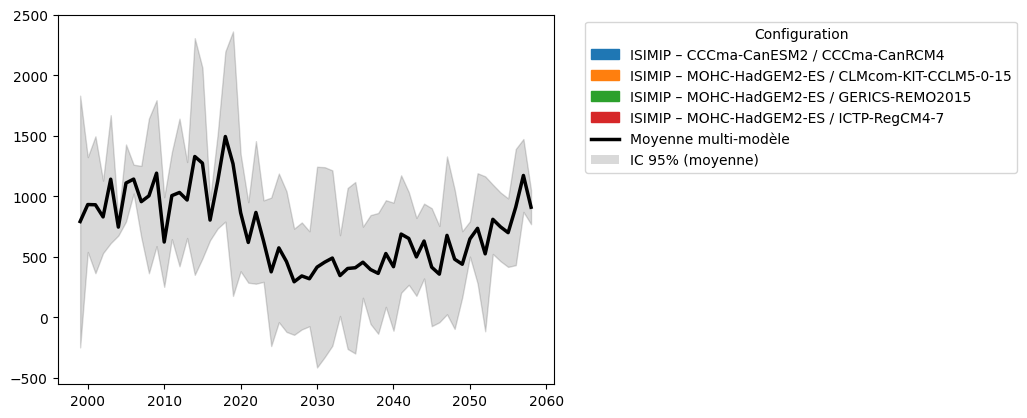

In [14]:
import numpy as np
import xarray as xr
from matplotlib.lines import Line2D

# --- (optionnel) s'assurer d'un jeu d'années commun ---
years_lists = [data_by_config[c]["year"].values for c in configs]
if len(years_lists) > 1:
    from functools import reduce
    common_years = reduce(np.intersect1d, years_lists)
    common_years = np.sort(common_years)
else:
    common_years = years

# --- Construire l'ensemble des moyennes spatiales par config ---
member_means = []
member_labels = []
for config in configs:
    da = data_by_config[config]                       # (year, pixel)
    da = da.sel(year=common_years)                    # aligne sur les années communes
    m = da.mean(dim="pixel")                          # (year,)
    member_means.append(m.assign_coords(member=f"{config[0]}|{config[1]}"))
    member_labels.append(f"{config[0]} – {config[1]}")

# empilement sur la dimension "member": (year, member)
ens = xr.concat(member_means, dim="member")

# --- Moyenne multi-modèle ---
mmm = ens.mean(dim="member")                          # (year,)

# --- IC 95% de la moyenne multi-modèle (t-Student) ---
n = ens.sizes["member"]
std = ens.std(dim="member", ddof=1)                   # écart-type inter-membres
sem = std / np.sqrt(n)                                # erreur standard
try:
    from scipy.stats import t
    tcrit = t.ppf(0.975, df=n-1)
except Exception:
    tcrit = 1.96                                      # approximation normale si SciPy absent

ci_low = (mmm - tcrit * sem).values
ci_high = (mmm + tcrit * sem).values

# --- (alternatif) dispersion inter-membres : bornes 5–95 % ---
q05 = ens.quantile(0.05, dim="member").values
q95 = ens.quantile(0.95, dim="member").values

# --- Tracé existant (vos courbes par config) ---
# ... (votre boucle for i, config in enumerate(configs):) ...

# --- Ajout de la moyenne multi-modèle + IC ---
plt.plot(common_years, mmm.values, color="black", linewidth=2.5, label="Moyenne multi‑modèle")
plt.fill_between(common_years, ci_low, ci_high, color="black", alpha=0.15, label="IC 95% (moyenne)")

# (option, si vous préférez montrer la dispersion des membres plutôt que l'IC de la moyenne)
# plt.fill_between(common_years, q05, q95, color="black", alpha=0.08, label="Plage 5–95 % des membres")

# --- Légende : ajoutez des entrées pour la moyenne multi-modèle ---
legend_handles = [Patch(color=colors[i % len(colors)], label=lab) for i, lab in enumerate(member_labels)]
legend_handles.append(Line2D([0], [0], color="black", lw=2.5, label="Moyenne multi‑modèle"))
legend_handles.append(Patch(facecolor="black", alpha=0.15, label="IC 95% (moyenne)"))
plt.legend(handles=legend_handles, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")


#### calcul de tendance

In [16]:
from scipy.stats import norm

def hamed_rao_with_sen_slope(x):
    x = np.asarray(x)
    x = x[~np.isnan(x)]  # supprime les NaNs
    n = len(x)
    
    if n < 2:
        return np.nan, np.nan, np.nan

    # Sen's slope
    slopes = []
    for i in range(n - 1):
        for j in range(i + 1, n):
            slopes.append((x[j] - x[i]) / (j - i))
    if len(slopes) == 0:
        return np.nan, np.nan, np.nan
    sen_slope = np.median(slopes)

    # Mann-Kendall S
    s = 0
    for k in range(n - 1):
        s += np.sum(np.sign(x[k+1:] - x[k]))

    unique_x, tp = np.unique(x, return_counts=True)
    var_s = (n*(n-1)*(2*n+5) - np.sum(tp*(tp-1)*(2*tp+5))) / 18

    if var_s == 0:
        return np.nan, np.nan, np.nan

    if s > 0:
        z = (s - 1) / np.sqrt(var_s)
    elif s < 0:
        z = (s + 1) / np.sqrt(var_s)
    else:
        z = 0

    p = 2 * (1 - norm.cdf(abs(z)))
    trend = 1.0 if z > 1.96 else -1.0 if z < -1.96 else 0.0

    return sen_slope, p, trend


In [ ]:
sen = {}
pval = {}
trend = {}

for correction, full_model in model_cases:
    

    sen_slope_da, pval_da, trend_da = xr.apply_ufunc(
        hamed_rao_with_sen_slope,
        results_dict[(correction, full_model)]["data"],
        input_core_dims=[["year"]],
        output_core_dims=[[], [], []],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float, float, float], 
    )

    # Carte pente de Sen
    sen_slope_da.plot(cmap="coolwarm")
    plt.title("Pente de Sen par pixel, " + correction + " - " + full_model)
    plt.show()

    # Carte de tendance significative
    trend_da.where(pval_da < 0.05).plot(cmap="bwr", vmin=-1, vmax=1)
    plt.title("Tendance significative (p < 0.05), " + correction + " - " + full_model)
    plt.show()

    # Stockage des résultats
    sen[(correction, full_model)] = sen_slope_da
    pval[(correction, full_model)] = pval_da
    trend[(correction, full_model)] = trend_da

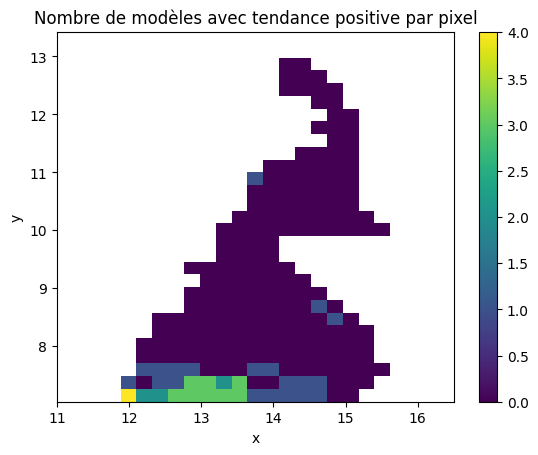

In [18]:
# compute the sum of the positive trends
trend_sum = xr.concat([trend_da for _, trend_da in trend.items()], dim="correction_model")
trend_sum = trend_sum.where(trend_sum > 0).sum(dim="correction_model")
xr.where(np.isnan(results_dict[(correction, full_model)]["data"].mean(axis=0)), np.nan, trend_sum).plot(cmap="viridis")
plt.title("Nombre de modèles avec tendance positive par pixel")
plt.show()

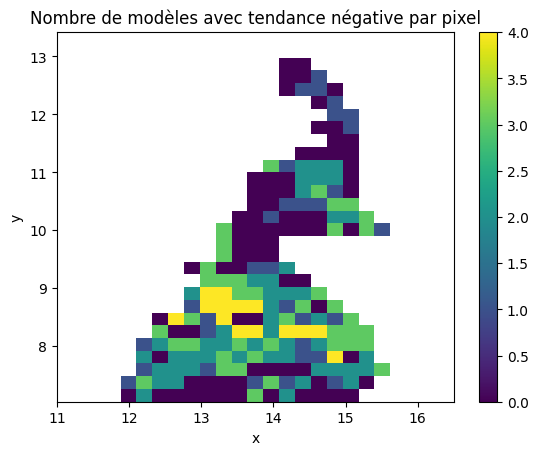

In [19]:
# compute the sum of the negative trends
trend_sum = xr.concat([trend_da for _, trend_da in trend.items()], dim="correction_model")
trend_sum = np.abs(trend_sum).where(trend_sum < 0).sum(dim="correction_model")
xr.where(np.isnan(results_dict[(correction, full_model)]["data"].mean(axis=0)), np.nan, trend_sum).plot(cmap="viridis")
plt.title("Nombre de modèles avec tendance négative par pixel")
plt.show()

### plots en relatif

#### normalisation locale

In [ ]:
# normlisation locale
results_dict_relatif_loc = {key: value.copy() for key, value in results_dict.items()}
for correction, full_model in model_cases:
    results_dict_relatif_loc[correction, full_model]["data"] = results_dict[correction, full_model]["data"] / results_dict[correction, full_model]["data"][0:24].mean(dim=["year"])

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Liste des années (supposées identiques pour tous)
years = results_dict_relatif_loc[model_cases[0]]["data"]["year"].values
n_years = len(years)

# Configurations (correction + modèle)
configs = list(model_cases)
n_configs = len(configs)

# Préparer les données pour chaque config
data_by_config = {}
for config in configs:
    da = results_dict_relatif_loc[config]["data"]  # dims: (year, y, x)
    flattened = da.stack(pixel=("y", "x"))  # dims: (year, pixel)
    data_by_config[config] = flattened  # garde pour plus tard

# Paramètres pour le boxplot
bar_width = 0.8 / n_configs
x_base = np.arange(n_years)  # 1 par année
colors = plt.cm.tab10.colors  # 10 couleurs distinctes

# Créer la figure
plt.figure(figsize=(14, 6))

for i, config in enumerate(configs):
    offset = (i - (n_configs - 1) / 2) * bar_width
    color = colors[i % len(colors)]
    
    # Pour chaque année, récupérer les rendements par pixel
    box_data = []
    positions = []
    for j, year in enumerate(years):
        vals = data_by_config[config].sel(year=year).values
        box_data.append(vals[~np.isnan(vals)])
        positions.append(x_base[j] + offset)
    
    # Tracer les boîtes à moustaches
    plt.boxplot(
        box_data,
        positions=positions,
        widths=bar_width * 0.9,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.5),
        medianprops=dict(color='black'),
        whiskerprops=dict(color=color),
        capprops=dict(color=color),
        flierprops=dict(marker='o', markersize=0, alpha=0.3)
    )

# Mise en forme
plt.xticks(x_base, years, rotation=45)
plt.xlabel("Année")
plt.ylabel("Rendement")
plt.title("Distribution spatiale du rendement relatif par année et modèle")
plt.grid(True, linestyle='--', alpha=0.3)
plt.ylim(-1, 8)  # Ajuster la limite pour la normalisation

# Légende manuelle
from matplotlib.patches import Patch
legend_patches = [Patch(color=colors[i % len(colors)], label=f"{c} – {m}") for i, (c, m) in enumerate(configs)]
plt.legend(handles=legend_patches, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Liste des années
years = results_dict_relatif_loc[model_cases[0]]["data"]["year"].values
n_years = len(years)

# Configurations
configs = list(model_cases)
colors = plt.cm.tab10.colors

# Préparer les données : (year, pixel) pour chaque config
data_by_config = {}
for config in configs:
    da = results_dict_relatif_loc[config]["data"]  # (year, y, x)
    flattened = da.stack(pixel=("y", "x"))  # (year, pixel)
    data_by_config[config] = flattened

# Créer la figure
plt.figure(figsize=(14, 6))

for i, config in enumerate(configs):
    color = colors[i % len(colors)]
    label = f"{config[0]} – {config[1]}"
    da = data_by_config[config]  # (year, pixel)

    # Calculs : moyenne, P25 et P75 ou écart-type
    mean_vals = da.mean(dim="pixel").values
    q25 = da.quantile(0.25, dim="pixel").values
    q75 = da.quantile(0.75, dim="pixel").values
    # std = da.std(dim="pixel").values
    # ymin = mean_vals - std
    # ymax = mean_vals + std

    # Tracer la courbe moyenne
    plt.plot(years, mean_vals, color=color, label=label)
    # Tracer le ribbon (intervalle interquartile)
    plt.fill_between(years, q25, q75, color=color, alpha=0.2)

# Mise en forme
plt.xlabel("Année")
plt.ylabel("Rendement moyen spatial")
plt.title("Évolution du rendement relatif moyen avec intervalle interquartile")
plt.grid(True, linestyle='--', alpha=0.3)
plt.xticks(years, rotation=45)

# Légende
legend_patches = [Patch(color=colors[i % len(colors)], label=f"{c} – {m}") for i, (c, m) in enumerate(configs)]
plt.legend(handles=legend_patches, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()

plt.show()


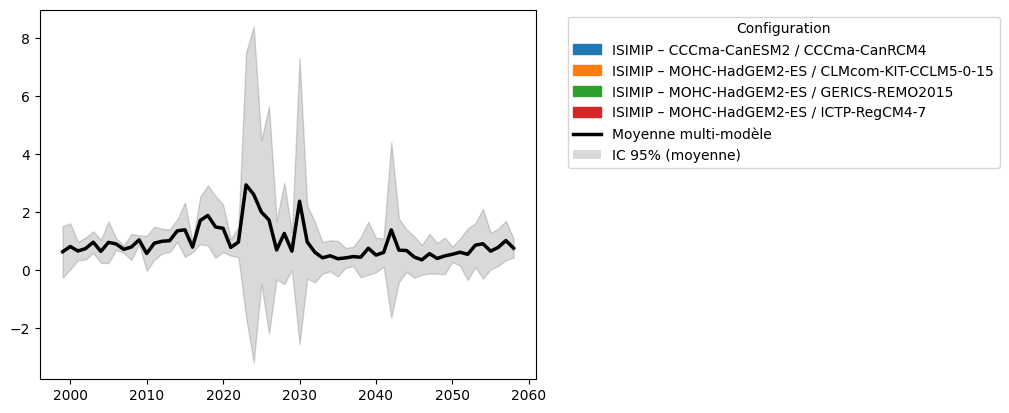

In [57]:
import numpy as np
import xarray as xr
from matplotlib.lines import Line2D

# --- (optionnel) s'assurer d'un jeu d'années commun ---
years_lists = [data_by_config[c]["year"].values for c in configs]
if len(years_lists) > 1:
    from functools import reduce
    common_years = reduce(np.intersect1d, years_lists)
    common_years = np.sort(common_years)
else:
    common_years = years

# --- Construire l'ensemble des moyennes spatiales par config ---
member_means = []
member_labels = []
for config in configs:
    da = data_by_config[config]                       # (year, pixel)
    da = da.sel(year=common_years)                    # aligne sur les années communes
    m = da.mean(dim="pixel")                          # (year,)
    member_means.append(m.assign_coords(member=f"{config[0]}|{config[1]}"))
    member_labels.append(f"{config[0]} – {config[1]}")

# empilement sur la dimension "member": (year, member)
ens = xr.concat(member_means, dim="member")

# --- Moyenne multi-modèle ---
mmm = ens.mean(dim="member")                          # (year,)

# --- IC 95% de la moyenne multi-modèle (t-Student) ---
n = ens.sizes["member"]
std = ens.std(dim="member", ddof=1)                   # écart-type inter-membres
sem = std / np.sqrt(n)                                # erreur standard
try:
    from scipy.stats import t
    tcrit = t.ppf(0.975, df=n-1)
except Exception:
    tcrit = 1.96                                      # approximation normale si SciPy absent

ci_low = (mmm - tcrit * sem).values
ci_high = (mmm + tcrit * sem).values

# --- (alternatif) dispersion inter-membres : bornes 5–95 % ---
q05 = ens.quantile(0.05, dim="member").values
q95 = ens.quantile(0.95, dim="member").values

# --- Tracé existant (vos courbes par config) ---
# ... (votre boucle for i, config in enumerate(configs):) ...

# --- Ajout de la moyenne multi-modèle + IC ---
plt.plot(common_years, mmm.values, color="black", linewidth=2.5, label="Moyenne multi‑modèle")
plt.fill_between(common_years, ci_low, ci_high, color="black", alpha=0.15, label="IC 95% (moyenne)")

# (option, si vous préférez montrer la dispersion des membres plutôt que l'IC de la moyenne)
# plt.fill_between(common_years, q05, q95, color="black", alpha=0.08, label="Plage 5–95 % des membres")

# --- Légende : ajoutez des entrées pour la moyenne multi-modèle ---
legend_handles = [Patch(color=colors[i % len(colors)], label=lab) for i, lab in enumerate(member_labels)]
legend_handles.append(Line2D([0], [0], color="black", lw=2.5, label="Moyenne multi‑modèle"))
legend_handles.append(Patch(facecolor="black", alpha=0.15, label="IC 95% (moyenne)"))
plt.legend(handles=legend_handles, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")


In [ ]:
sen = {}
pval = {}
trend = {}

for correction, full_model in model_cases:
    

    sen_slope_da, pval_da, trend_da = xr.apply_ufunc(
        hamed_rao_with_sen_slope,
        results_dict_relatif_loc[(correction, full_model)]["data"],
        input_core_dims=[["year"]],
        output_core_dims=[[], [], []],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float, float, float], 
    )

    # Carte pente de Sen
    sen_slope_da.plot(cmap="coolwarm")
    plt.title("Pente de Sen par pixel, " + correction + " - " + full_model)
    plt.show()

    # Carte de tendance significative
    trend_da.where(pval_da < 0.05).plot(cmap="bwr", vmin=-1, vmax=1)
    plt.title("Tendance significative (p < 0.05), " + correction + " - " + full_model)
    plt.show()

    # Stockage des résultats
    sen[(correction, full_model)] = sen_slope_da
    pval[(correction, full_model)] = pval_da
    trend[(correction, full_model)] = trend_da

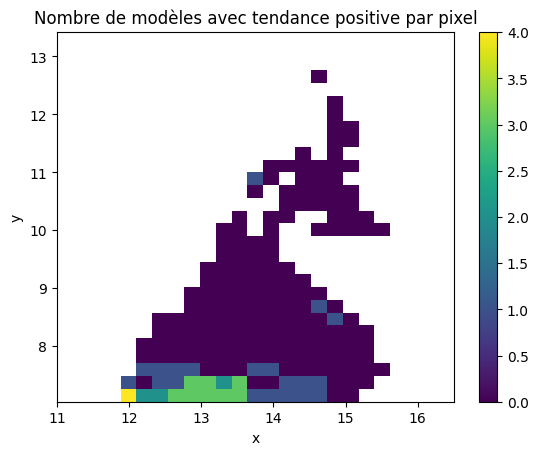

In [59]:
# compute the sum of the positive trends
trend_sum = xr.concat([trend_da for _, trend_da in trend.items()], dim="correction_model")
trend_sum = trend_sum.where(trend_sum > 0).sum(dim="correction_model")
xr.where(np.isnan(results_dict[(correction, full_model)]["data"].mean(axis=0)), np.nan, trend_sum).plot(cmap="viridis")
plt.title("Nombre de modèles avec tendance positive par pixel")
plt.show()

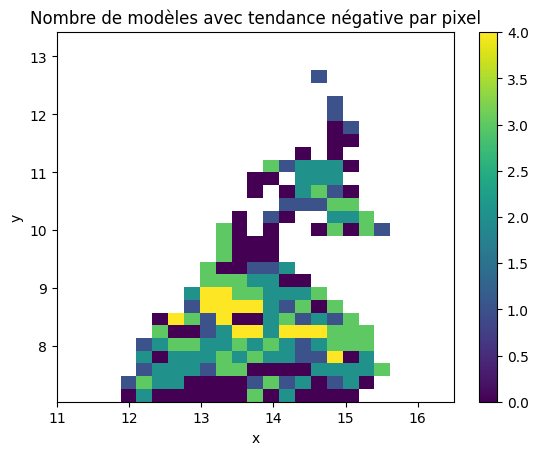

In [60]:
# compute the sum of the negative trends
trend_sum = xr.concat([trend_da for _, trend_da in trend.items()], dim="correction_model")
trend_sum = np.abs(trend_sum).where(trend_sum < 0).sum(dim="correction_model")
xr.where(np.isnan(results_dict[(correction, full_model)]["data"].mean(axis=0)), np.nan, trend_sum).plot(cmap="viridis")
plt.title("Nombre de modèles avec tendance négative par pixel")
plt.show()

#### normalisation régionale

In [ ]:
# normlisation regionale
results_dict_relatif_reg = {key: value.copy() for key, value in results_dict.items()}
for correction, full_model in model_cases:
    results_dict_relatif_reg[correction, full_model]["data"] = results_dict[correction, full_model]["data"] / results_dict[correction, full_model]["data"][0:24].mean()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Liste des années (supposées identiques pour tous)
years = results_dict_relatif_reg[model_cases[0]]["data"]["year"].values
n_years = len(years)

# Configurations (correction + modèle)
configs = list(model_cases)
n_configs = len(configs)

# Préparer les données pour chaque config
data_by_config = {}
for config in configs:
    da = results_dict_relatif_reg[config]["data"]  # dims: (year, y, x)
    flattened = da.stack(pixel=("y", "x"))  # dims: (year, pixel)
    data_by_config[config] = flattened  # garde pour plus tard

# Paramètres pour le boxplot
bar_width = 0.8 / n_configs
x_base = np.arange(n_years)  # 1 par année
colors = plt.cm.tab10.colors  # 10 couleurs distinctes

# Créer la figure
plt.figure(figsize=(14, 6))

for i, config in enumerate(configs):
    offset = (i - (n_configs - 1) / 2) * bar_width
    color = colors[i % len(colors)]
    
    # Pour chaque année, récupérer les rendements par pixel
    box_data = []
    positions = []
    for j, year in enumerate(years):
        vals = data_by_config[config].sel(year=year).values
        box_data.append(vals[~np.isnan(vals)])
        positions.append(x_base[j] + offset)
    
    # Tracer les boîtes à moustaches
    plt.boxplot(
        box_data,
        positions=positions,
        widths=bar_width * 0.9,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.5),
        medianprops=dict(color='black'),
        whiskerprops=dict(color=color),
        capprops=dict(color=color),
        flierprops=dict(marker='o', markersize=0, alpha=0.3)
    )

# Mise en forme
plt.xticks(x_base, years, rotation=45)
plt.xlabel("Année")
plt.ylabel("Rendement")
plt.title("Distribution spatiale du rendement relatif regional par année et modèle")
plt.grid(True, linestyle='--', alpha=0.3)
plt.ylim(-1, 8)  # Ajuster la limite pour la normalisation

# Légende manuelle
from matplotlib.patches import Patch
legend_patches = [Patch(color=colors[i % len(colors)], label=f"{c} – {m}") for i, (c, m) in enumerate(configs)]
plt.legend(handles=legend_patches, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Liste des années
years = results_dict_relatif_reg[model_cases[0]]["data"]["year"].values
n_years = len(years)

# Configurations
configs = list(model_cases)
colors = plt.cm.tab10.colors

# Préparer les données : (year, pixel) pour chaque config
data_by_config = {}
for config in configs:
    da = results_dict_relatif_reg[config]["data"]  # (year, y, x)
    flattened = da.stack(pixel=("y", "x"))  # (year, pixel)
    data_by_config[config] = flattened

# Créer la figure
plt.figure(figsize=(14, 6))

for i, config in enumerate(configs):
    color = colors[i % len(colors)]
    label = f"{config[0]} – {config[1]}"
    da = data_by_config[config]  # (year, pixel)

    # Calculs : moyenne, P25 et P75 ou écart-type
    mean_vals = da.mean(dim="pixel").values
    q25 = da.quantile(0.25, dim="pixel").values
    q75 = da.quantile(0.75, dim="pixel").values
    # std = da.std(dim="pixel").values
    # ymin = mean_vals - std
    # ymax = mean_vals + std

    # Tracer la courbe moyenne
    plt.plot(years, mean_vals, color=color, label=label)
    # Tracer le ribbon (intervalle interquartile)
    plt.fill_between(years, q25, q75, color=color, alpha=0.2)

# Mise en forme
plt.xlabel("Année")
plt.ylabel("Rendement moyen spatial")
plt.title("Évolution du rendement relatif regional moyen avec intervalle interquartile")
plt.grid(True, linestyle='--', alpha=0.3)
plt.xticks(years, rotation=45)

# Légende
legend_patches = [Patch(color=colors[i % len(colors)], label=f"{c} – {m}") for i, (c, m) in enumerate(configs)]
plt.legend(handles=legend_patches, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()

plt.show()


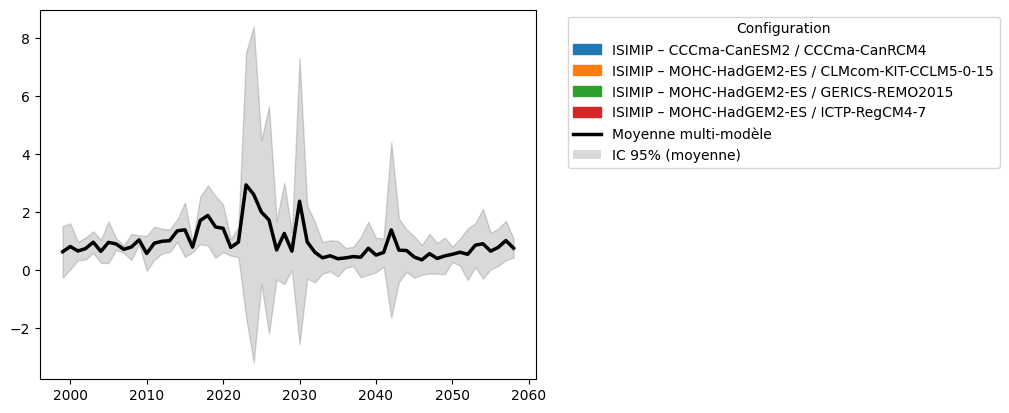

In [64]:
import numpy as np
import xarray as xr
from matplotlib.lines import Line2D

# --- (optionnel) s'assurer d'un jeu d'années commun ---
years_lists = [data_by_config[c]["year"].values for c in configs]
if len(years_lists) > 1:
    from functools import reduce
    common_years = reduce(np.intersect1d, years_lists)
    common_years = np.sort(common_years)
else:
    common_years = years

# --- Construire l'ensemble des moyennes spatiales par config ---
member_means = []
member_labels = []
for config in configs:
    da = data_by_config[config]                       # (year, pixel)
    da = da.sel(year=common_years)                    # aligne sur les années communes
    m = da.mean(dim="pixel")                          # (year,)
    member_means.append(m.assign_coords(member=f"{config[0]}|{config[1]}"))
    member_labels.append(f"{config[0]} – {config[1]}")

# empilement sur la dimension "member": (year, member)
ens = xr.concat(member_means, dim="member")

# --- Moyenne multi-modèle ---
mmm = ens.mean(dim="member")                          # (year,)

# --- IC 95% de la moyenne multi-modèle (t-Student) ---
n = ens.sizes["member"]
std = ens.std(dim="member", ddof=1)                   # écart-type inter-membres
sem = std / np.sqrt(n)                                # erreur standard
try:
    from scipy.stats import t
    tcrit = t.ppf(0.975, df=n-1)
except Exception:
    tcrit = 1.96                                      # approximation normale si SciPy absent

ci_low = (mmm - tcrit * sem).values
ci_high = (mmm + tcrit * sem).values

# --- (alternatif) dispersion inter-membres : bornes 5–95 % ---
q05 = ens.quantile(0.05, dim="member").values
q95 = ens.quantile(0.95, dim="member").values

# --- Tracé existant (vos courbes par config) ---
# ... (votre boucle for i, config in enumerate(configs):) ...

# --- Ajout de la moyenne multi-modèle + IC ---
plt.plot(common_years, mmm.values, color="black", linewidth=2.5, label="Moyenne multi‑modèle")
plt.fill_between(common_years, ci_low, ci_high, color="black", alpha=0.15, label="IC 95% (moyenne)")

# (option, si vous préférez montrer la dispersion des membres plutôt que l'IC de la moyenne)
# plt.fill_between(common_years, q05, q95, color="black", alpha=0.08, label="Plage 5–95 % des membres")

# --- Légende : ajoutez des entrées pour la moyenne multi-modèle ---
legend_handles = [Patch(color=colors[i % len(colors)], label=lab) for i, lab in enumerate(member_labels)]
legend_handles.append(Line2D([0], [0], color="black", lw=2.5, label="Moyenne multi‑modèle"))
legend_handles.append(Patch(facecolor="black", alpha=0.15, label="IC 95% (moyenne)"))
plt.legend(handles=legend_handles, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")


In [ ]:
sen = {}
pval = {}
trend = {}

for correction, full_model in model_cases:
    

    sen_slope_da, pval_da, trend_da = xr.apply_ufunc(
        hamed_rao_with_sen_slope,
        results_dict_relatif_reg[(correction, full_model)]["data"],
        input_core_dims=[["year"]],
        output_core_dims=[[], [], []],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float, float, float], 
    )

    # Carte pente de Sen
    sen_slope_da.plot(cmap="coolwarm")
    plt.title("Pente de Sen par pixel, " + correction + " - " + full_model)
    plt.show()

    # Carte de tendance significative
    trend_da.where(pval_da < 0.05).plot(cmap="bwr", vmin=-1, vmax=1)
    plt.title("Tendance significative (p < 0.05), " + correction + " - " + full_model)
    plt.show()

    # Stockage des résultats
    sen[(correction, full_model)] = sen_slope_da
    pval[(correction, full_model)] = pval_da
    trend[(correction, full_model)] = trend_da

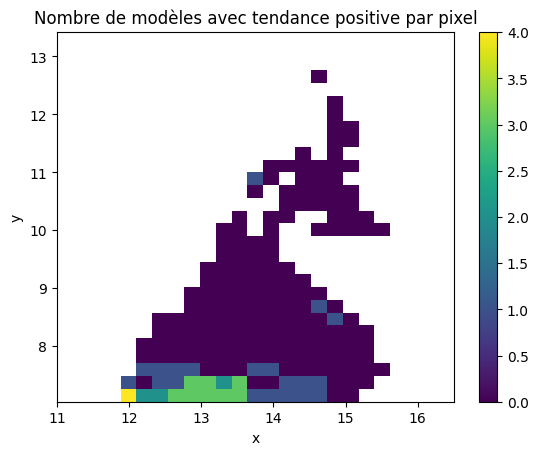

In [66]:
# compute the sum of the positive trends
trend_sum = xr.concat([trend_da for _, trend_da in trend.items()], dim="correction_model")
trend_sum = trend_sum.where(trend_sum > 0).sum(dim="correction_model")
xr.where(np.isnan(results_dict[(correction, full_model)]["data"].mean(axis=0)), np.nan, trend_sum).plot(cmap="viridis")
plt.title("Nombre de modèles avec tendance positive par pixel")
plt.show()

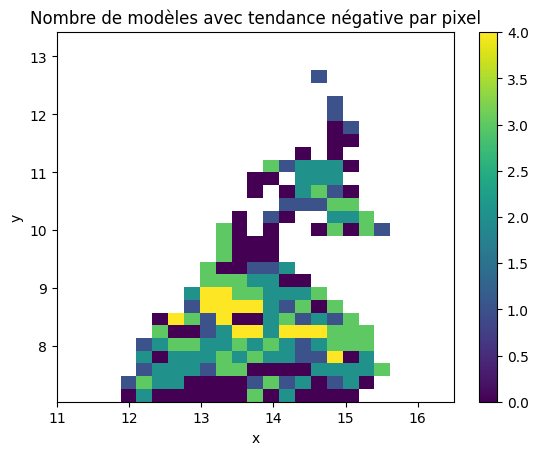

In [67]:
# compute the sum of the negative trends
trend_sum = xr.concat([trend_da for _, trend_da in trend.items()], dim="correction_model")
trend_sum = np.abs(trend_sum).where(trend_sum < 0).sum(dim="correction_model")
xr.where(np.isnan(results_dict[(correction, full_model)]["data"].mean(axis=0)), np.nan, trend_sum).plot(cmap="viridis")
plt.title("Nombre de modèles avec tendance négative par pixel")
plt.show()

#### anomalies de rendement locale

In [ ]:
# anomalie par pixel
results_dict_anomalie_loc = {key: value.copy() for key, value in results_dict.items()}
for correction, full_model in model_cases:
    results_dict_anomalie_loc[correction, full_model]["data"] = results_dict[correction, full_model]["data"] - results_dict[correction, full_model]["data"][0:24].mean(dim="year")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Liste des années (supposées identiques pour tous)
years = results_dict_anomalie_loc[model_cases[0]]["data"]["year"].values
n_years = len(years)

# Configurations (correction + modèle)
configs = list(model_cases)
n_configs = len(configs)

# Préparer les données pour chaque config
data_by_config = {}
for config in configs:
    da = results_dict_anomalie_loc[config]["data"]  # dims: (year, y, x)
    flattened = da.stack(pixel=("y", "x"))  # dims: (year, pixel)
    data_by_config[config] = flattened  # garde pour plus tard

# Paramètres pour le boxplot
bar_width = 0.8 / n_configs
x_base = np.arange(n_years)  # 1 par année
colors = plt.cm.tab10.colors  # 10 couleurs distinctes

# Créer la figure
plt.figure(figsize=(14, 6))

for i, config in enumerate(configs):
    offset = (i - (n_configs - 1) / 2) * bar_width
    color = colors[i % len(colors)]
    
    # Pour chaque année, récupérer les rendements par pixel
    box_data = []
    positions = []
    for j, year in enumerate(years):
        vals = data_by_config[config].sel(year=year).values
        box_data.append(vals[~np.isnan(vals)])
        positions.append(x_base[j] + offset)
    
    # Tracer les boîtes à moustaches
    plt.boxplot(
        box_data,
        positions=positions,
        widths=bar_width * 0.9,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.5),
        medianprops=dict(color='black'),
        whiskerprops=dict(color=color),
        capprops=dict(color=color),
        flierprops=dict(marker='o', markersize=0, alpha=0.3)
    )

# Mise en forme
plt.xticks(x_base, years, rotation=45)
plt.xlabel("Année")
plt.ylabel("Rendement")
plt.title("Distribution de l'anomalie de rendement par année et modèle")
plt.grid(True, linestyle='--', alpha=0.3)
plt.ylim(-6, 6)  # Ajuster la limite pour la normalisation

# Légende manuelle
from matplotlib.patches import Patch
legend_patches = [Patch(color=colors[i % len(colors)], label=f"{c} – {m}") for i, (c, m) in enumerate(configs)]
plt.legend(handles=legend_patches, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Liste des années
years = results_dict_anomalie_loc[model_cases[0]]["data"]["year"].values
n_years = len(years)

# Configurations
configs = list(model_cases)
colors = plt.cm.tab10.colors

# Préparer les données : (year, pixel) pour chaque config
data_by_config = {}
for config in configs:
    da = results_dict_anomalie_loc[config]["data"]  # (year, y, x)
    flattened = da.stack(pixel=("y", "x"))  # (year, pixel)
    data_by_config[config] = flattened

# Créer la figure
plt.figure(figsize=(14, 6))

for i, config in enumerate(configs):
    color = colors[i % len(colors)]
    label = f"{config[0]} – {config[1]}"
    da = data_by_config[config]  # (year, pixel)

    # Calculs : moyenne, P25 et P75 ou écart-type
    mean_vals = da.mean(dim="pixel").values
    q25 = da.quantile(0.25, dim="pixel").values
    q75 = da.quantile(0.75, dim="pixel").values
    # std = da.std(dim="pixel").values
    # ymin = mean_vals - std
    # ymax = mean_vals + std

    # Tracer la courbe moyenne
    plt.plot(years, mean_vals, color=color, label=label)
    # Tracer le ribbon (intervalle interquartile)
    plt.fill_between(years, q25, q75, color=color, alpha=0.2)

# Mise en forme
plt.xlabel("Année")
plt.ylabel("Rendement moyen spatial")
plt.title("Évolution du rendement relatif regional moyen avec intervalle interquartile")
plt.grid(True, linestyle='--', alpha=0.3)
plt.xticks(years, rotation=45)

# Légende
legend_patches = [Patch(color=colors[i % len(colors)], label=f"{c} – {m}") for i, (c, m) in enumerate(configs)]
plt.legend(handles=legend_patches, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()

plt.show()


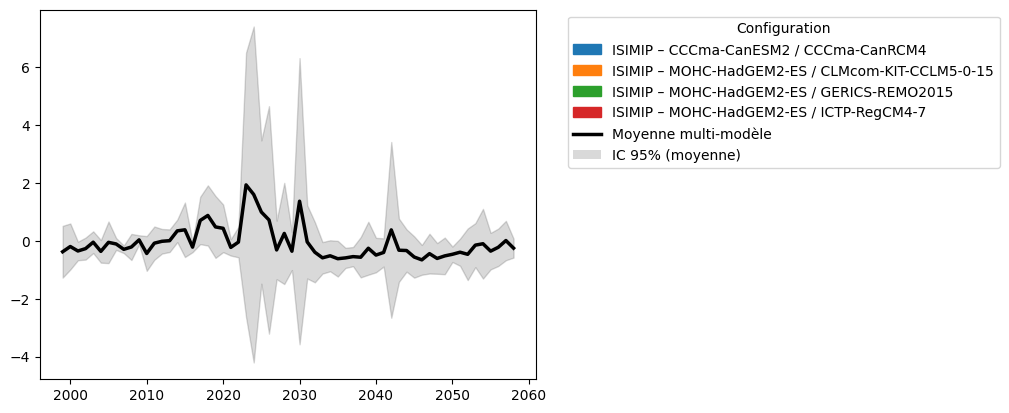

In [77]:
import numpy as np
import xarray as xr
from matplotlib.lines import Line2D

# --- (optionnel) s'assurer d'un jeu d'années commun ---
years_lists = [data_by_config[c]["year"].values for c in configs]
if len(years_lists) > 1:
    from functools import reduce
    common_years = reduce(np.intersect1d, years_lists)
    common_years = np.sort(common_years)
else:
    common_years = years

# --- Construire l'ensemble des moyennes spatiales par config ---
member_means = []
member_labels = []
for config in configs:
    da = data_by_config[config]                       # (year, pixel)
    da = da.sel(year=common_years)                    # aligne sur les années communes
    m = da.mean(dim="pixel")                          # (year,)
    member_means.append(m.assign_coords(member=f"{config[0]}|{config[1]}"))
    member_labels.append(f"{config[0]} – {config[1]}")

# empilement sur la dimension "member": (year, member)
ens = xr.concat(member_means, dim="member")

# --- Moyenne multi-modèle ---
mmm = ens.mean(dim="member")                          # (year,)

# --- IC 95% de la moyenne multi-modèle (t-Student) ---
n = ens.sizes["member"]
std = ens.std(dim="member", ddof=1)                   # écart-type inter-membres
sem = std / np.sqrt(n)                                # erreur standard
try:
    from scipy.stats import t
    tcrit = t.ppf(0.975, df=n-1)
except Exception:
    tcrit = 1.96                                      # approximation normale si SciPy absent

ci_low = (mmm - tcrit * sem).values
ci_high = (mmm + tcrit * sem).values

# --- (alternatif) dispersion inter-membres : bornes 5–95 % ---
q05 = ens.quantile(0.05, dim="member").values
q95 = ens.quantile(0.95, dim="member").values

# --- Tracé existant (vos courbes par config) ---
# ... (votre boucle for i, config in enumerate(configs):) ...

# --- Ajout de la moyenne multi-modèle + IC ---
plt.plot(common_years, mmm.values, color="black", linewidth=2.5, label="Moyenne multi‑modèle")
plt.fill_between(common_years, ci_low, ci_high, color="black", alpha=0.15, label="IC 95% (moyenne)")

# (option, si vous préférez montrer la dispersion des membres plutôt que l'IC de la moyenne)
# plt.fill_between(common_years, q05, q95, color="black", alpha=0.08, label="Plage 5–95 % des membres")

# --- Légende : ajoutez des entrées pour la moyenne multi-modèle ---
legend_handles = [Patch(color=colors[i % len(colors)], label=lab) for i, lab in enumerate(member_labels)]
legend_handles.append(Line2D([0], [0], color="black", lw=2.5, label="Moyenne multi‑modèle"))
legend_handles.append(Patch(facecolor="black", alpha=0.15, label="IC 95% (moyenne)"))
plt.legend(handles=legend_handles, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")


In [ ]:
sen = {}
pval = {}
trend = {}

for correction, full_model in model_cases:
    

    sen_slope_da, pval_da, trend_da = xr.apply_ufunc(
        hamed_rao_with_sen_slope,
        results_dict_anomalie_loc[(correction, full_model)]["data"],
        input_core_dims=[["year"]],
        output_core_dims=[[], [], []],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float, float, float], 
    )

    # Carte pente de Sen
    sen_slope_da.plot(cmap="coolwarm")
    plt.title("Pente de Sen par pixel, " + correction + " - " + full_model)
    plt.show()

    # Carte de tendance significative
    trend_da.where(pval_da < 0.05).plot(cmap="bwr", vmin=-1, vmax=1)
    plt.title("Tendance significative (p < 0.05), " + correction + " - " + full_model)
    plt.show()

    # Stockage des résultats
    sen[(correction, full_model)] = sen_slope_da
    pval[(correction, full_model)] = pval_da
    trend[(correction, full_model)] = trend_da

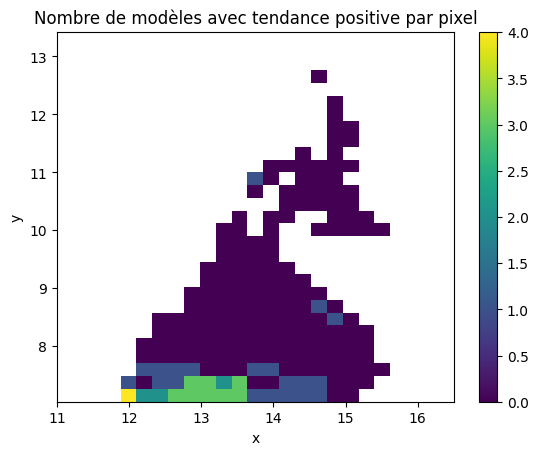

In [79]:
# compute the sum of the positive trends
trend_sum = xr.concat([trend_da for _, trend_da in trend.items()], dim="correction_model")
trend_sum = trend_sum.where(trend_sum > 0).sum(dim="correction_model")
xr.where(np.isnan(results_dict[(correction, full_model)]["data"].mean(axis=0)), np.nan, trend_sum).plot(cmap="viridis")
plt.title("Nombre de modèles avec tendance positive par pixel")
plt.show()

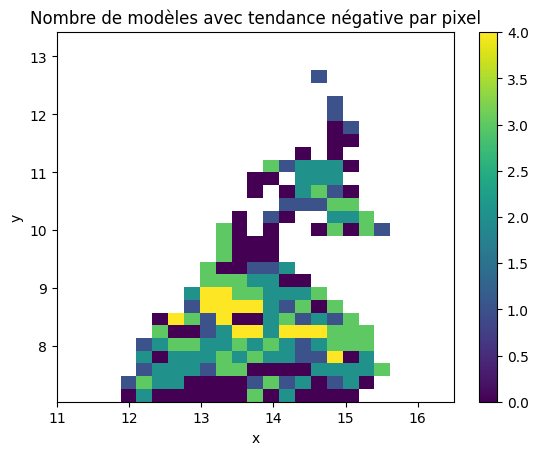

In [80]:
# compute the sum of the negative trends
trend_sum = xr.concat([trend_da for _, trend_da in trend.items()], dim="correction_model")
trend_sum = np.abs(trend_sum).where(trend_sum < 0).sum(dim="correction_model")
xr.where(np.isnan(results_dict[(correction, full_model)]["data"].mean(axis=0)), np.nan, trend_sum).plot(cmap="viridis")
plt.title("Nombre de modèles avec tendance négative par pixel")
plt.show()

#### anomalies de rendement regionale

In [ ]:
# anomalie par pixel
results_dict_anomalie_reg = {key: value.copy() for key, value in results_dict.items()}
for correction, full_model in model_cases:
    results_dict_anomalie_reg[correction, full_model]["data"] = results_dict[correction, full_model]["data"] - results_dict[correction, full_model]["data"][0:24].mean()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Liste des années (supposées identiques pour tous)
years = results_dict_anomalie_reg[model_cases[0]]["data"]["year"].values
n_years = len(years)

# Configurations (correction + modèle)
configs = list(model_cases)
n_configs = len(configs)

# Préparer les données pour chaque config
data_by_config = {}
for config in configs:
    da = results_dict_anomalie_reg[config]["data"]  # dims: (year, y, x)
    flattened = da.stack(pixel=("y", "x"))  # dims: (year, pixel)
    data_by_config[config] = flattened  # garde pour plus tard

# Paramètres pour le boxplot
bar_width = 0.8 / n_configs
x_base = np.arange(n_years)  # 1 par année
colors = plt.cm.tab10.colors  # 10 couleurs distinctes

# Créer la figure
plt.figure(figsize=(14, 6))

for i, config in enumerate(configs):
    offset = (i - (n_configs - 1) / 2) * bar_width
    color = colors[i % len(colors)]
    
    # Pour chaque année, récupérer les rendements par pixel
    box_data = []
    positions = []
    for j, year in enumerate(years):
        vals = data_by_config[config].sel(year=year).values
        box_data.append(vals[~np.isnan(vals)])
        positions.append(x_base[j] + offset)
    
    # Tracer les boîtes à moustaches
    plt.boxplot(
        box_data,
        positions=positions,
        widths=bar_width * 0.9,
        patch_artist=True,
        boxprops=dict(facecolor=color, alpha=0.5),
        medianprops=dict(color='black'),
        whiskerprops=dict(color=color),
        capprops=dict(color=color),
        flierprops=dict(marker='o', markersize=0, alpha=0.3)
    )

# Mise en forme
plt.xticks(x_base, years, rotation=45)
plt.xlabel("Année")
plt.ylabel("Rendement")
plt.title("Distribution de l'anomalie de rendement par année et modèle")
plt.grid(True, linestyle='--', alpha=0.3)
plt.ylim(-6, 6)  # Ajuster la limite pour la normalisation

# Légende manuelle
from matplotlib.patches import Patch
legend_patches = [Patch(color=colors[i % len(colors)], label=f"{c} – {m}") for i, (c, m) in enumerate(configs)]
plt.legend(handles=legend_patches, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

# Liste des années
years = results_dict_anomalie_reg[model_cases[0]]["data"]["year"].values
n_years = len(years)

# Configurations
configs = list(model_cases)
colors = plt.cm.tab10.colors

# Préparer les données : (year, pixel) pour chaque config
data_by_config = {}
for config in configs:
    da = results_dict_anomalie_reg[config]["data"]  # (year, y, x)
    flattened = da.stack(pixel=("y", "x"))  # (year, pixel)
    data_by_config[config] = flattened

# Créer la figure
plt.figure(figsize=(14, 6))

for i, config in enumerate(configs):
    color = colors[i % len(colors)]
    label = f"{config[0]} – {config[1]}"
    da = data_by_config[config]  # (year, pixel)

    # Calculs : moyenne, P25 et P75 ou écart-type
    mean_vals = da.mean(dim="pixel").values
    q25 = da.quantile(0.25, dim="pixel").values
    q75 = da.quantile(0.75, dim="pixel").values
    # std = da.std(dim="pixel").values
    # ymin = mean_vals - std
    # ymax = mean_vals + std

    # Tracer la courbe moyenne
    plt.plot(years, mean_vals, color=color, label=label)
    # Tracer le ribbon (intervalle interquartile)
    plt.fill_between(years, q25, q75, color=color, alpha=0.2)

# Mise en forme
plt.xlabel("Année")
plt.ylabel("Rendement moyen spatial")
plt.title("Évolution du rendement relatif regional moyen avec intervalle interquartile")
plt.grid(True, linestyle='--', alpha=0.3)
plt.xticks(years, rotation=45)

# Légende
legend_patches = [Patch(color=colors[i % len(colors)], label=f"{c} – {m}") for i, (c, m) in enumerate(configs)]
plt.legend(handles=legend_patches, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()

plt.show()


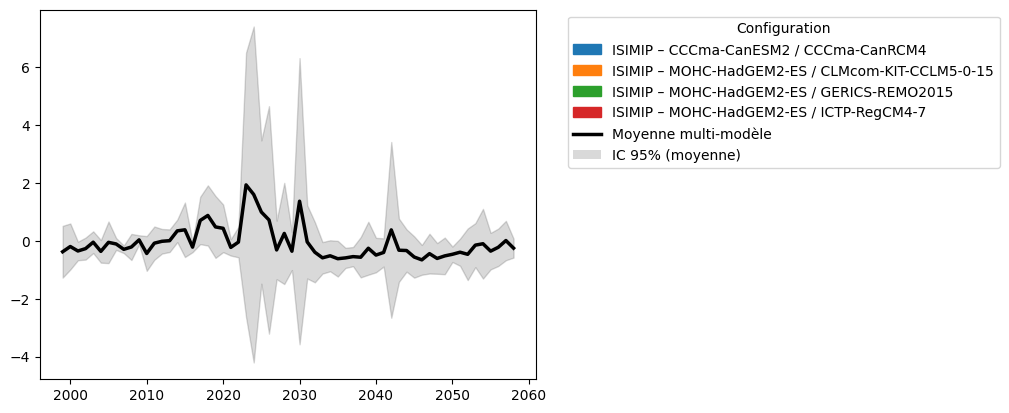

In [ ]:
import numpy as np
import xarray as xr
from matplotlib.lines import Line2D

# --- (optionnel) s'assurer d'un jeu d'années commun ---
years_lists = [data_by_config[c]["year"].values for c in configs]
if len(years_lists) > 1:
    from functools import reduce
    common_years = reduce(np.intersect1d, years_lists)
    common_years = np.sort(common_years)
else:
    common_years = years

# --- Construire l'ensemble des moyennes spatiales par config ---
member_means = []
member_labels = []
for config in configs:
    da = data_by_config[config]                       # (year, pixel)
    da = da.sel(year=common_years)                    # aligne sur les années communes
    m = da.mean(dim="pixel")                          # (year,)
    member_means.append(m.assign_coords(member=f"{config[0]}|{config[1]}"))
    member_labels.append(f"{config[0]} – {config[1]}")

# empilement sur la dimension "member": (year, member)
ens = xr.concat(member_means, dim="member")

# --- Moyenne multi-modèle ---
mmm = ens.mean(dim="member")                          # (year,)

# --- IC 95% de la moyenne multi-modèle (t-Student) ---
n = ens.sizes["member"]
std = ens.std(dim="member", ddof=1)                   # écart-type inter-membres
sem = std / np.sqrt(n)                                # erreur standard
try:
    from scipy.stats import t
    tcrit = t.ppf(0.975, df=n-1)
except Exception:
    tcrit = 1.96                                      # approximation normale si SciPy absent

ci_low = (mmm - tcrit * sem).values
ci_high = (mmm + tcrit * sem).values

# --- (alternatif) dispersion inter-membres : bornes 5–95 % ---
q05 = ens.quantile(0.05, dim="member").values
q95 = ens.quantile(0.95, dim="member").values

# --- Tracé existant (vos courbes par config) ---
# ... (votre boucle for i, config in enumerate(configs):) ...

# --- Ajout de la moyenne multi-modèle + IC ---
plt.plot(common_years, mmm.values, color="black", linewidth=2.5, label="Moyenne multi‑modèle")
plt.fill_between(common_years, ci_low, ci_high, color="black", alpha=0.15, label="IC 95% (moyenne)")

# (option, si vous préférez montrer la dispersion des membres plutôt que l'IC de la moyenne)
# plt.fill_between(common_years, q05, q95, color="black", alpha=0.08, label="Plage 5–95 % des membres")

# --- Légende : ajoutez des entrées pour la moyenne multi-modèle ---
legend_handles = [Patch(color=colors[i % len(colors)], label=lab) for i, lab in enumerate(member_labels)]
legend_handles.append(Line2D([0], [0], color="black", lw=2.5, label="Moyenne multi‑modèle"))
legend_handles.append(Patch(facecolor="black", alpha=0.15, label="IC 95% (moyenne)"))
plt.legend(handles=legend_handles, title="Configuration", bbox_to_anchor=(1.05, 1), loc="upper left")


In [ ]:
sen = {}
pval = {}
trend = {}

for correction, full_model in model_cases:
    

    sen_slope_da, pval_da, trend_da = xr.apply_ufunc(
        hamed_rao_with_sen_slope,
        results_dict_anomalie_reg[(correction, full_model)]["data"],
        input_core_dims=[["year"]],
        output_core_dims=[[], [], []],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float, float, float], 
    )

    # Carte pente de Sen
    sen_slope_da.plot(cmap="coolwarm")
    plt.title("Pente de Sen par pixel, " + correction + " - " + full_model)
    plt.show()

    # Carte de tendance significative
    trend_da.where(pval_da < 0.05).plot(cmap="bwr", vmin=-1, vmax=1)
    plt.title("Tendance significative (p < 0.05), " + correction + " - " + full_model)
    plt.show()

    # Stockage des résultats
    sen[(correction, full_model)] = sen_slope_da
    pval[(correction, full_model)] = pval_da
    trend[(correction, full_model)] = trend_da

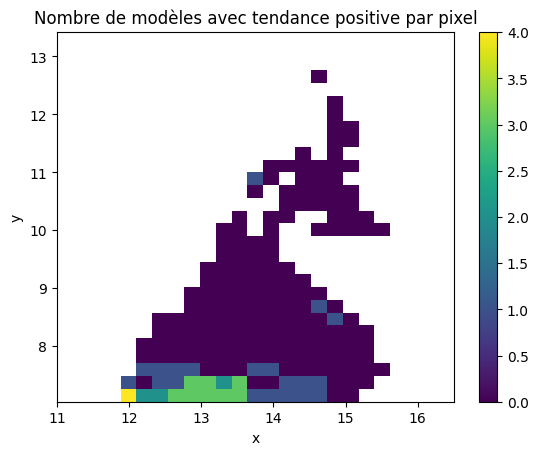

In [ ]:
# compute the sum of the positive trends
trend_sum = xr.concat([trend_da for _, trend_da in trend.items()], dim="correction_model")
trend_sum = trend_sum.where(trend_sum > 0).sum(dim="correction_model")
xr.where(np.isnan(results_dict[(correction, full_model)]["data"].mean(axis=0)), np.nan, trend_sum).plot(cmap="viridis")
plt.title("Nombre de modèles avec tendance positive par pixel")
plt.show()

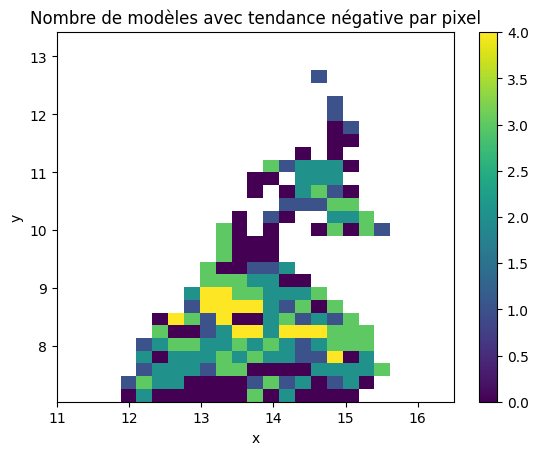

In [ ]:
# compute the sum of the negative trends
trend_sum = xr.concat([trend_da for _, trend_da in trend.items()], dim="correction_model")
trend_sum = np.abs(trend_sum).where(trend_sum < 0).sum(dim="correction_model")
xr.where(np.isnan(results_dict[(correction, full_model)]["data"].mean(axis=0)), np.nan, trend_sum).plot(cmap="viridis")
plt.title("Nombre de modèles avec tendance négative par pixel")
plt.show()